<a href="https://colab.research.google.com/github/Sanhith30/ITA0605-ML/blob/main/Lab%20Exercises/Exp14_House_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 14: House Price Prediction
**Course:** ITA06 - Machine Learning (Lab)

## Aim
Implement House Price Prediction using an appropriate machine learning algorithm.

## Background
House price prediction is a classic *regression* task. We compare **Linear, Ridge, Lasso, Random Forest and Gradient Boosting** regressors. Regularised linear models (Ridge L2, Lasso L1) reduce overfitting; ensembles capture non-linear effects and interactions (e.g. a big house is worth much more in a premium locality). The best model is tuned with **GridSearchCV**.



## Setup: Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
np.random.seed(42)
print("Libraries imported successfully")

Libraries imported successfully


## Step 1: Data Collection
We generate a dataset of **2,000 houses** (price in lakh INR) with area, bedrooms, bathrooms, age, distance to city centre, locality tier, parking, furnishing and floor. Price depends on these with realistic non-linear effects (locality multiplies the value of area; value falls with age and distance). Saved as `house_data.csv`.

In [2]:
rng = np.random.RandomState(42)
n = 2000

area = np.clip(rng.normal(1500, 600, n), 400, 5000).round(0)
bedrooms = np.clip(np.round(area / 600 + rng.normal(0, 0.6, n)), 1, 6).astype(int)
bathrooms = np.clip(bedrooms - rng.randint(0, 2, n), 1, 5)
age = rng.randint(0, 40, n)
distance = np.clip(rng.lognormal(2.0, 0.6, n), 1, 45).round(1)
locality = rng.choice(["Premium", "Mid", "Budget"], n, p=[0.2, 0.5, 0.3])
parking = rng.randint(0, 3, n)
furnishing = rng.choice(["Unfurnished", "Semi-furnished", "Furnished"], n, p=[0.4, 0.4, 0.2])
floor = rng.randint(0, 21, n)

loc_mult = pd.Series(locality).map({"Premium": 1.6, "Mid": 1.0, "Budget": 0.7}).values
furn_add = pd.Series(furnishing).map({"Unfurnished": 0, "Semi-furnished": 4, "Furnished": 9}).values
price = (area * 0.045 * loc_mult * np.exp(-0.008 * age) * np.exp(-0.012 * distance)
         + 3 * bathrooms + 4 * parking + furn_add + 0.3 * floor) * rng.lognormal(0, 0.08, n)

pd.DataFrame({"Area_sqft": area, "Bedrooms": bedrooms, "Bathrooms": bathrooms, "Age_years": age,
              "Distance_to_city_km": distance, "Locality": locality, "Parking": parking,
              "Furnishing": furnishing, "Floor": floor, "Price_Lakhs": price.round(2)}).to_csv("house_data.csv", index=False)
print("Saved house_data.csv")

Saved house_data.csv


## Step 2: Data Loading

In [3]:
df = pd.read_csv("house_data.csv")
df.head()

,Area_sqft,Bedrooms,Bathrooms,Age_years,Distance_to_city_km,Locality,Parking,Furnishing,Floor,Price_Lakhs
0,1798.0,3,2,25,7.2,Premium,1,Unfurnished,8,105.66
1,1417.0,2,2,29,3.9,Mid,2,Unfurnished,7,68.52
2,1889.0,3,2,15,13.9,Mid,0,Furnished,9,85.40
3,2414.0,4,3,6,11.2,Budget,0,Unfurnished,3,71.37
4,1360.0,1,1,15,16.2,Budget,1,Furnished,19,64.93


## Step 3: Data Preprocessing
Remove duplicates, check for missing values, treat extreme outliers, split the data and build the preprocessing transformer (scale numeric, one-hot encode categorical).

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

print("Missing values:", df.isnull().sum().sum(), "| Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()

# Outlier check using the IQR rule on the target
q1, q3 = df["Price_Lakhs"].quantile([0.25, 0.75]); iqr = q3 - q1
upper = q3 + 3 * iqr
print("Extreme-price houses (> Q3 + 3*IQR):", (df["Price_Lakhs"] > upper).sum(), "(kept: they are legitimate large houses)")

target = "Price_Lakhs"
num_cols = ["Area_sqft", "Bedrooms", "Bathrooms", "Age_years", "Distance_to_city_km", "Parking", "Floor"]
cat_cols = ["Locality", "Furnishing"]
X, y = df[num_cols + cat_cols], df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
preprocessor = ColumnTransformer([("num", StandardScaler(), num_cols), ("cat", OneHotEncoder(drop="first"), cat_cols)])
print("Train:", X_train.shape, "Test:", X_test.shape)

Missing values: 0 | Duplicates: 0
Extreme-price houses (> Q3 + 3*IQR): 4 (kept: they are legitimate large houses)
Train: (1600, 9) Test: (400, 9)


## Step 4: Exploratory Data Analysis (EDA)

In [5]:
print(df.describe().T.round(2))

                      count     mean     std     min      25%      50%  \
Area_sqft            2000.0  1533.57  578.09  400.00  1126.00  1526.50   
Bedrooms             2000.0     2.59    1.11    1.00     2.00     3.00   
Bathrooms            2000.0     2.17    1.09    1.00     1.00     2.00   
Age_years            2000.0    19.44   11.31    0.00    10.00    19.00   
Distance_to_city_km  2000.0     8.81    5.58    1.00     4.90     7.50   
Parking              2000.0     0.99    0.81    0.00     0.00     1.00   
Floor                2000.0     9.87    5.97    0.00     5.00    10.00   
Price_Lakhs          2000.0    72.24   31.73   13.73    49.75    67.18   

                         75%     max  
Area_sqft            1909.75  3812.0  
Bedrooms                3.00     6.0  
Bathrooms               3.00     5.0  
Age_years              29.00    39.0  
Distance_to_city_km    11.00    45.0  
Parking                 2.00     2.0  
Floor                  15.00    20.0  
Price_Lakhs          

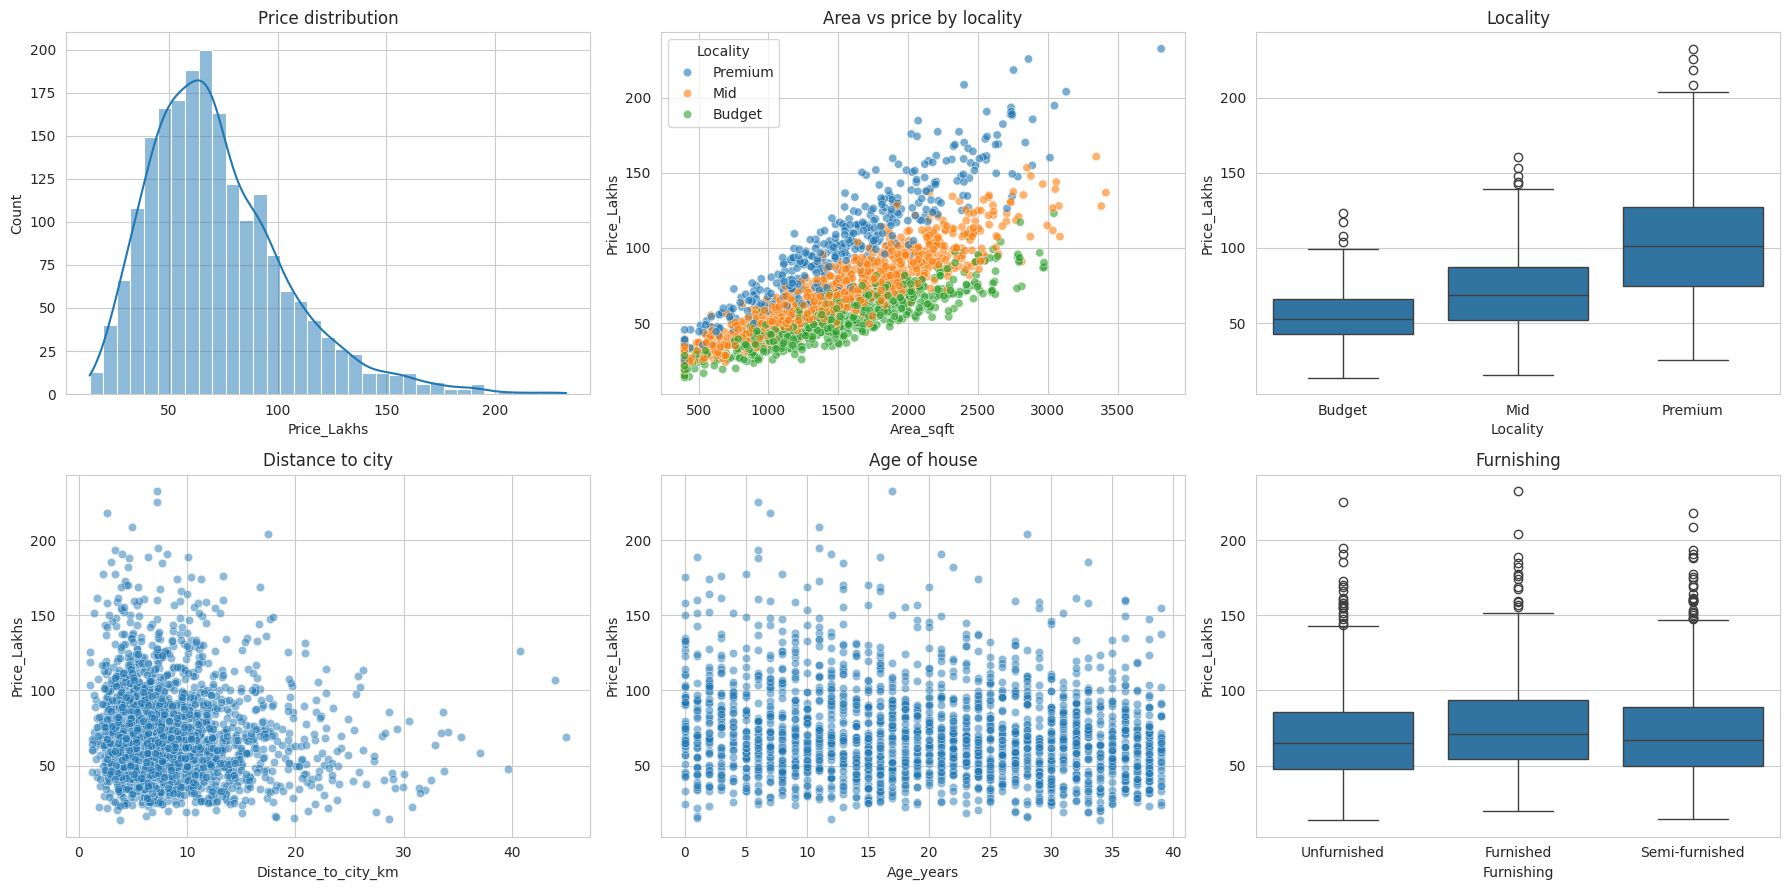

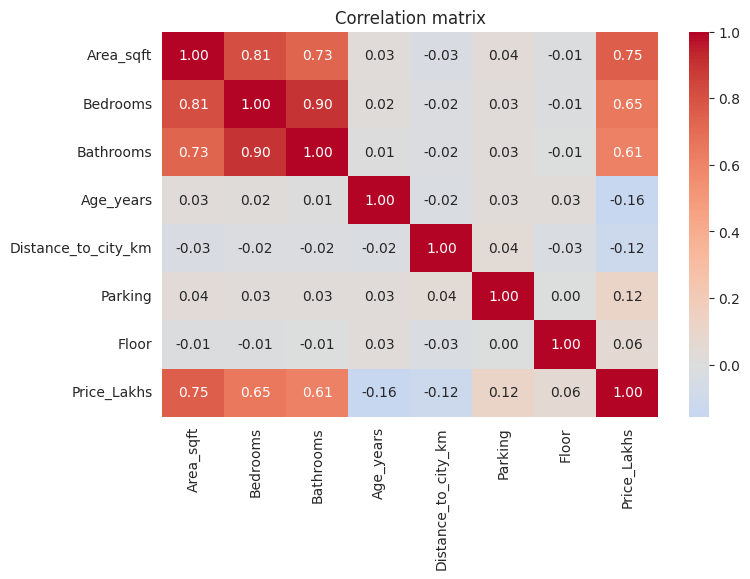

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
sns.histplot(df[target], kde=True, ax=axes[0, 0]); axes[0, 0].set_title("Price distribution")
sns.scatterplot(data=df, x="Area_sqft", y=target, hue="Locality", alpha=.6, ax=axes[0, 1]); axes[0, 1].set_title("Area vs price by locality")
sns.boxplot(data=df, x="Locality", y=target, order=["Budget", "Mid", "Premium"], ax=axes[0, 2]); axes[0, 2].set_title("Locality")
sns.scatterplot(data=df, x="Distance_to_city_km", y=target, alpha=.5, ax=axes[1, 0]); axes[1, 0].set_title("Distance to city")
sns.scatterplot(data=df, x="Age_years", y=target, alpha=.5, ax=axes[1, 1]); axes[1, 1].set_title("Age of house")
sns.boxplot(data=df, x="Furnishing", y=target, ax=axes[1, 2]); axes[1, 2].set_title("Furnishing")
plt.tight_layout(); plt.show()

sns.heatmap(df[num_cols + [target]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0); plt.title("Correlation matrix"); plt.show()

## Step 5: Model Training
Train five regressors on `log(price)` (prices are skewed and effects are multiplicative); predictions are converted back automatically.

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

def make(reg):
    return TransformedTargetRegressor(regressor=Pipeline([("prep", preprocessor), ("model", reg)]),
                                      func=np.log1p, inverse_func=np.expm1)

models = {
    "Linear": make(LinearRegression()),
    "Ridge": make(Ridge(alpha=1.0)),
    "Lasso": make(Lasso(alpha=0.001)),
    "Random Forest": make(RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)),
    "Gradient Boosting": make(GradientBoostingRegressor(random_state=42)),
}
for m in models.values():
    m.fit(X_train, y_train)
print("Trained:", list(models))

Trained: ['Linear', 'Ridge', 'Lasso', 'Random Forest', 'Gradient Boosting']


## Step 6: Model Evaluation
Compare all models, then **tune** the best family with grid search and inspect residuals and importance.

                     MAE    RMSE     R2
Model                                  
Gradient Boosting  5.630   7.518  0.946
Random Forest      6.592   8.844  0.926
Lasso              7.343  10.881  0.888
Linear             7.380  11.010  0.885
Ridge              7.378  10.992  0.885


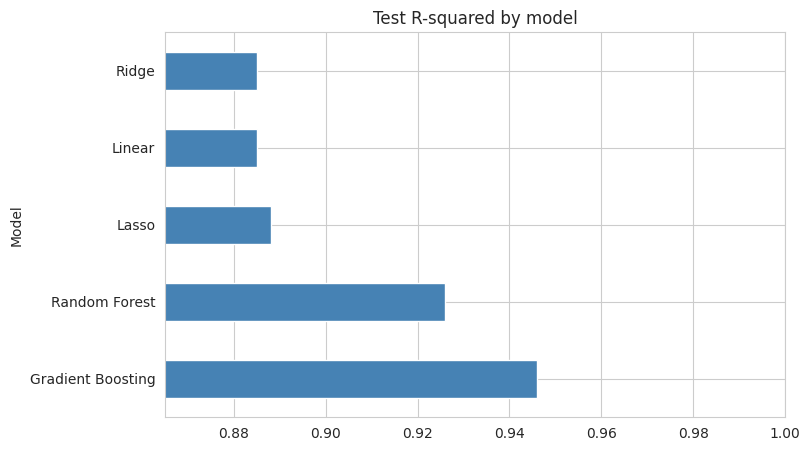

In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

rows = []
for name, m in models.items():
    p = m.predict(X_test)
    rows.append({"Model": name, "MAE": mean_absolute_error(y_test, p), "RMSE": np.sqrt(mean_squared_error(y_test, p)), "R2": r2_score(y_test, p)})
results = pd.DataFrame(rows).set_index("Model").round(3).sort_values("R2", ascending=False)
print(results)
results["R2"].plot(kind="barh", color="steelblue", title="Test R-squared by model"); plt.xlim(results["R2"].min() - 0.02, 1); plt.show()

Best parameters: {'regressor__model__learning_rate': 0.1, 'regressor__model__max_depth': 2, 'regressor__model__n_estimators': 200}
Tuned Gradient Boosting -> MAE=5.384  RMSE=7.213  R2=0.9506


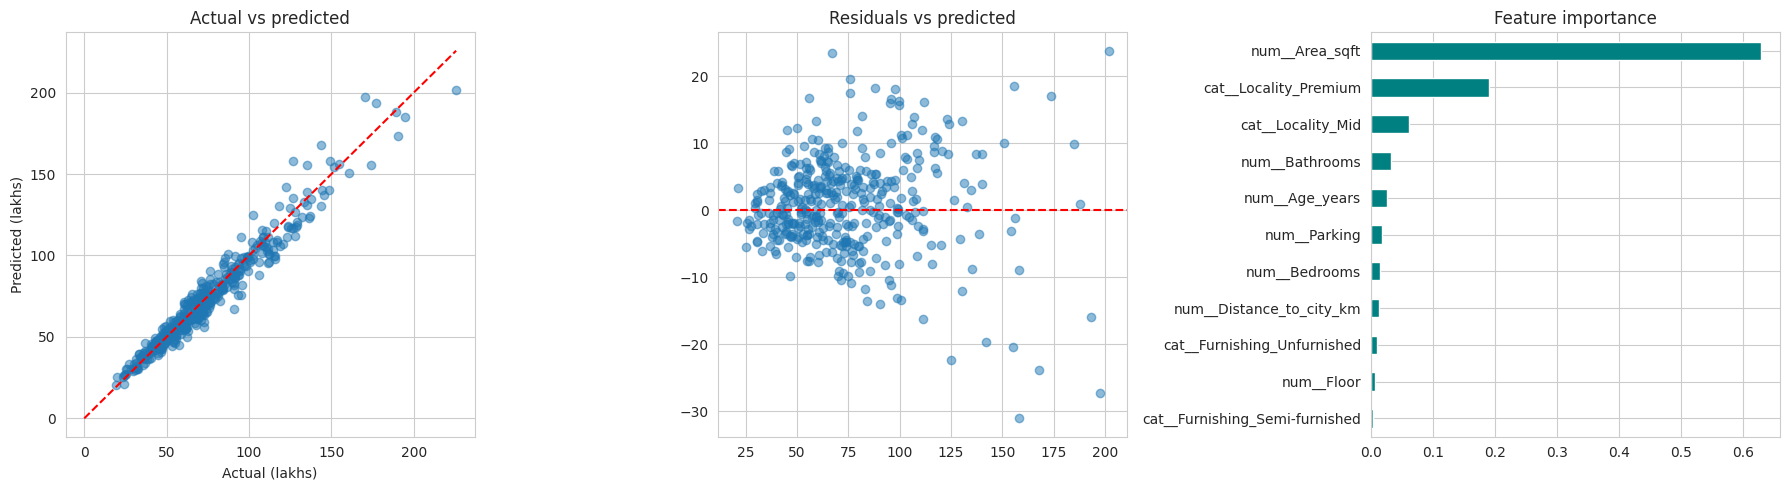

In [9]:
from sklearn.model_selection import GridSearchCV

param_grid = {"regressor__model__n_estimators": [100, 200],
              "regressor__model__max_depth": [2, 3, 4],
              "regressor__model__learning_rate": [0.05, 0.1]}
search = GridSearchCV(make(GradientBoostingRegressor(random_state=42)), param_grid, cv=3, scoring="r2", n_jobs=-1).fit(X_train, y_train)
tuned = search.best_estimator_
print("Best parameters:", search.best_params_)
p = tuned.predict(X_test)
print(f"Tuned Gradient Boosting -> MAE={mean_absolute_error(y_test, p):.3f}  RMSE={np.sqrt(mean_squared_error(y_test, p)):.3f}  R2={r2_score(y_test, p):.4f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(y_test, p, alpha=.5); lim = [0, max(y_test.max(), p.max())]; axes[0].plot(lim, lim, "r--")
axes[0].set_xlabel("Actual (lakhs)"); axes[0].set_ylabel("Predicted (lakhs)"); axes[0].set_title("Actual vs predicted")
axes[1].scatter(p, y_test - p, alpha=.5); axes[1].axhline(0, color="r", linestyle="--"); axes[1].set_title("Residuals vs predicted")
names = tuned.regressor_.named_steps["prep"].get_feature_names_out()
pd.Series(tuned.regressor_.named_steps["model"].feature_importances_, index=names).sort_values().plot(kind="barh", ax=axes[2], color="teal")
axes[2].set_title("Feature importance")
plt.tight_layout(); plt.show()

## Step 7: Prediction on New Data

In [10]:
new_houses = pd.DataFrame([
    {"Area_sqft": 1200, "Bedrooms": 2, "Bathrooms": 2, "Age_years": 5,  "Distance_to_city_km": 6,  "Parking": 1, "Floor": 4,  "Locality": "Mid",     "Furnishing": "Semi-furnished"},
    {"Area_sqft": 2500, "Bedrooms": 4, "Bathrooms": 3, "Age_years": 2,  "Distance_to_city_km": 3,  "Parking": 2, "Floor": 10, "Locality": "Premium", "Furnishing": "Furnished"},
    {"Area_sqft": 900,  "Bedrooms": 2, "Bathrooms": 1, "Age_years": 25, "Distance_to_city_km": 20, "Parking": 0, "Floor": 1,  "Locality": "Budget",  "Furnishing": "Unfurnished"},
])
new_houses["Predicted_Price_Lakhs"] = tuned.predict(new_houses).round(1)
new_houses

,Area_sqft,Bedrooms,Bathrooms,Age_years,Distance_to_city_km,Parking,Floor,Locality,Furnishing,Predicted_Price_Lakhs
0,1200,2,2,5,6,1,4,Mid,Semi-furnished,63.6
1,2500,4,3,2,3,2,10,Premium,Furnished,201.3
2,900,2,1,25,20,0,1,Budget,Unfurnished,25.0


## Conclusion
Tree-based ensembles beat plain linear models because price depends on interactions (area x locality) and non-linear effects; the log-transformed linear models are still strong baselines and are easy to interpret. Area and locality are the dominant drivers, followed by distance to the city and age. Grid search gave a modest gain. For real data, also consider geographic coordinates, feature engineering (price per sq ft) and cross-validated model selection.